# Проверка гипотезы о различии времени активности пользователей Яндекс.Книг в Москве и Санкт-Петербурге

- Автор: Чахлова Елизавета
- Дата: 21.10.2026

**Цели и задачи проекта**

Цель проекта проверить проводят ли пользователи из Санкт-Петербурга в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы.

**Описание данных**

Поля таблицы: 
- `Unnamed: 0` - колонка без имени, вероятно порядковый номер строки
- `city` - город пользователя в котором он совершал чтение/прослушивание
- `puid` - идентификатор пользователя
- `hours` - сумма часов чтения и прослушивания

**Содержимое проекта**

1. Загрузка данных и знакомство с ними
2. Проверка гипотезы в Python
3. Аналитическая записка

### Загрузка данных и знакомство с ними

Загружаем данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# df = здесь была загрузка датасета

In [3]:
df.head(10)

,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434
5,5,Москва,352567,8.206369
6,6,Москва,439493,0.857758
7,7,Москва,494541,0.035072
8,8,Москва,647235,12.000076
9,9,Москва,656480,0.973032


In [4]:
df.duplicated('puid').sum()

244

In [5]:
dups = df[df.duplicated('puid', keep=False)]
dups.sort_values('puid')

,Unnamed: 0,city,puid,hours
35,35,Москва,2637041,10.317371
6247,6247,Санкт-Петербург,2637041,3.883926
134,134,Москва,9979490,32.415573
6274,6274,Санкт-Петербург,9979490,1.302997
145,145,Москва,10597984,42.931506
...,...,...,...,...
6195,6195,Москва,1130000020425037,0.310556
8775,8775,Санкт-Петербург,1130000023864516,14.384722
6202,6202,Москва,1130000023864516,142.830085
6210,6210,Москва,1130000028554332,11.277554


In [6]:
df.duplicated(['puid', 'city']).sum()

0

In [7]:
# считаем процент дублей от общих пользователей
all_users = df['puid'].nunique()
dups_count = dups['puid'].nunique()
dups_part = round((dups_count/all_users)*100, 2)
print (f'Доля мультигородских пользователей среди уникальных {dups_part}%')

Доля мультигородских пользователей среди уникальных 2.86%


#### Промежуточный вывод

В данных 244 дублей индентификаторов пользователей (puid). Дубли различаются городом, скорее всего это пользователи, которые живут на 2 города, часто путешествуют, либо ездят в командировки. При этом дубли с 'puid', 'city' отсутствуют.
У нас есть 2 вариант: 
- удалить дубли
- оставить дубли

Я выбираю **исключить пользователей совершавших чтение/прослушивание в обоих городах, чтобы обеспечить независимость групп**. Доля мультигородских пользователей среди уникальных 2.86%.

In [8]:
df_clean = df.drop_duplicates('puid', keep=False)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8296 entries, 0 to 8783
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8296 non-null   int64  
 1   city        8296 non-null   object 
 2   puid        8296 non-null   int64  
 3   hours       8296 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 324.1+ KB


In [9]:
# проверим, что не осталось пересечений пользователей между группами
intersection = (df_clean
 .groupby('puid')
 .agg({'city':'nunique'})
 .query('city > 1'))
len(intersection)

0

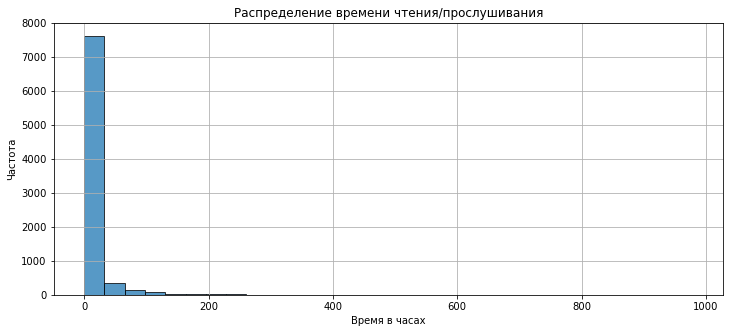

In [10]:
plt.figure(figsize=(12, 5))

# Строим гистограмму с помощью pandas через plot(kind='hist')
df_clean['hours'].plot(
                kind='hist', # Тип графика — гистограмма
                bins=30, # Устанавливаем количество корзин
                alpha=0.75,
                edgecolor='black',
)

# Настраиваем оформление графика
plt.title('Распределение времени чтения/прослушивания')
plt.xlabel('Время в часах')
plt.ylabel('Частота')

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

#### Промежуточный вывод

В интервале примерно от 250 до 1000 есть небольшие выбросы, которые практически не видны на графике. Их значения по оси Y малы, значит, к существенному искажению они не приводят, и их можно удалить. Оставим значения, которые будут меньше 99%-го процентиля этого ряда значений или равны ему.

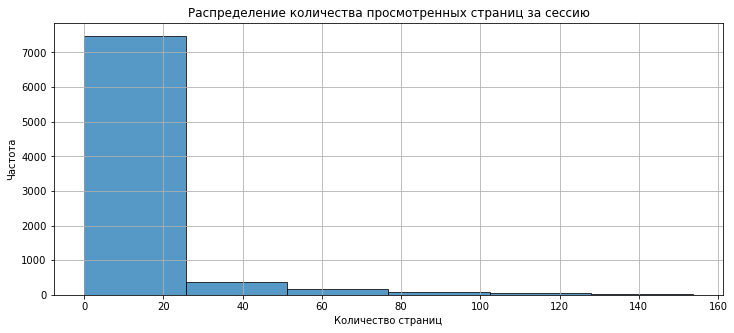

In [11]:
cleaned = df_clean[df_clean['hours'] <= df_clean['hours'].quantile(0.99)]['hours']

plt.figure(figsize=(12, 5))

# Строим гистограмму с помощью pandas через plot(kind='hist')
cleaned.plot(
                kind='hist', # Тип графика - гистограмма
                bins=6, # Устанавливаем количество корзин
                alpha=0.75,
                edgecolor='black',
)

# Настраиваем оформление графика
plt.title('Распределение количества просмотренных страниц за сессию')
plt.xlabel('Количество страниц')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show() 

In [12]:
df_new = df_clean[df_clean['hours'] <= df_clean['hours'].quantile(0.99)]

In [13]:
# считаем кол-во уникальных пользователей в каждой из групп
unique_users_test = df_new.groupby('city')['puid'].nunique()
unique_users_test

city
Москва             5929
Санкт-Петербург    2284
Name: puid, dtype: int64

In [14]:
p = 100*((unique_users_test.loc['Москва'] - unique_users_test.loc['Санкт-Петербург'])/unique_users_test.loc['Москва'])

print(f"Процентная разниме мужду группами составляет - {round(p, 2)}%")

Процентная разниме мужду группами составляет - 61.48%


In [15]:
df_new[df_new['city'] == 'Москва']['hours'].describe()

count    5929.000000
mean        8.064964
std        19.733973
min         0.000022
25%         0.055492
50%         0.856322
75%         5.639621
max       153.639891
Name: hours, dtype: float64

In [16]:
df_new[df_new['city'] == 'Санкт-Петербург']['hours'].describe()

count    2284.000000
mean        8.377901
std        19.723539
min         0.000025
25%         0.057032
50%         0.852310
75%         5.672186
max       152.338086
Name: hours, dtype: float64

#### Вывод

Процентная разница мужду группами составляет - 61.48%. В Москве - 5929, в Санкт-Петербурге - 2284. Но цисленная разница не нарушает принцип сопоставимости групп. 
    
Стандартное отклонение, среднее и медиана значительно не различаются в группах.

Москва: 
- mean        8.064964
- std        19.733973
- min         0.000022
- 25%         0.055492
- 50%         0.856322
- 75%         5.639621
- max       153.639891
    
Санкт-Петербург:
- mean        8.377901
- std        19.723539
- min         0.000025
- 25%         0.057032
- 50%         0.852310
- 75%         5.672186
- max       152.338086

### Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуем статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [17]:
# Разделение на группы: создаём две отдельные выборки для контрольной (A) и экспериментальной (B) групп
metric_a = df_new[df_new.city=='Москва']['hours'] # выборка целевой метрики для группы A
metric_b = df_new[df_new.city=='Санкт-Петербург']['hours'] # выборка целевой метрики для группы B

# На каком уровне значимости проверяем гипотезу о равенстве выборочных средних
alpha = 0.05 

stat_welch_ttest, p_value_welch_ttest = ttest_ind(
    metric_a, 
    metric_b, 
    equal_var=False,
    alternative='less' # Поскольку альтернативная гипотеза о том, что выборочное среднее первой выборки(metric_a) меньше второй выборки,
) # применяем t-тест Уэлча

if p_value_welch_ttest>alpha:
    print(f'p-value теста = {round(p_value_welch_ttest, 2)}')
    print('Нулевую гипотезу отклонить нельзя')
    print('Интерпретация: средняя активность  пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается')
else:
    print(f'p-value теста = {round(p_value_welch_ttest, 2)}')
    print('Нулевая гипотеза не находит подтверждения')
    print('Интерпретация: средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.')

p-value теста = 0.26
Нулевую гипотезу отклонить нельзя
Интерпретация: средняя активность  пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается


In [18]:
stat_mw, p_value_mw = mannwhitneyu(
    metric_a, 
    metric_b, 
    alternative='less'
)


if p_value_mw>alpha:
    print(f'p-value теста = {round(p_value_mw, 2)}')
    print('Нулевую гипотезу отклонить нельзя')
    print('Интерпретация: средняя активность  пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается')
else:
    print(f'p-value теста = {round(p_value_mw, 2)}')
    print('Нулевая гипотеза не находит подтверждения')
    print('Интерпретация: средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.')

p-value теста = 0.43
Нулевую гипотезу отклонить нельзя
Интерпретация: средняя активность  пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается


### Аналитическая записка

Для проверки гипотезы выбрала t-тест Уэлча и уровень значимости α = 0.05. Так же для надежности провела дополнительную проверку с помощью теста Манна — Уитни, так как данные у нас даже после отброса выборово по 99-му процентилю сильно скошены вправо.

По результатам теста Уэлча p-value составило 0.26, теста Манна — Уитни 0.43, что меньше заданного уровня значимости 0.05. А это означает, что средняя активность пользователей в Москве и Санкт-Петербурге не различается. 

Вероятно город не имеет большого влияение на среднюю активность пользователей.